# Deteksi Dini Mahasiswa Berisiko Gagal Sebelum Ujian Tengah/Akhir Semester

**Data:** Hasan, R., Palaniappan, S., Mahmood, S., Abbas, A., & Sarker, K. U. (2021). *Dataset of students' performance using student information system, Moodle and the mobile application "eDify"*. Data, 6(11), 110. Zenodo 5591907 (CC BY 4.0).

**Tujuan:** menguji seberapa baik kegagalan mahasiswa dapat dideteksi **sebelum ujian**, memakai informasi yang benar-benar tersedia bagi dosen pada titik keputusan itu, lalu membandingkannya dengan cara evaluasi studi sebelumnya (semua fitur + split acak).

| Titik keputusan | Informasi yang dipakai | Kapan tersedia |
|---|---|---|
| **T0 – Awal semester** | Data SIAKAD (IPK, status berisiko, riwayat mengulang, jumlah modul lain, prasyarat, riwayat plagiarisme) + mata kuliah | Minggu 1 |
| **T1 – Setelah tugas 1 (sebelum UTS)** | T0 + nilai tugas 1 (CW1) | Sebelum ujian tengah semester |
| **T1+ – T1 + aktivitas LMS dan video** | T1 + menit Moodle (kampus/luar) + interaksi video eDify | *Batas atas optimistis*: data aktivitas di dataset berupa total satu semester |
| **Penuh (replikasi studi lama)** | Semua fitur termasuk CW2 dan nilai UAS (ESE) | Akhir semester; **tidak bisa dipakai untuk deteksi dini** |

**Cara pakai:** jalankan `python download_data.py` sekali untuk mengunduh 77 file dataset dari Zenodo ke folder ini (atau unduh manual dari https://zenodo.org/records/5591907), lalu jalankan **Kernel → Restart & Run All**. Paket yang dibutuhkan ada di `requirements.txt`.

In [1]:
# 1. Persiapan
import os, re, glob, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, StratifiedGroupKFold
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, accuracy_score, recall_score, precision_score, f1_score
from sklearn.inspection import permutation_importance
warnings.filterwarnings('ignore')

FOLDER = r'F:\kuliah daring\hibah'
if os.path.isdir(FOLDER):
    os.chdir(FOLDER)
print('Folder kerja:', os.getcwd())

SEED = 2026
N_BOOT = 2000
rng = np.random.default_rng(SEED)

Folder kerja: /tmp/claude-0/-home-claude/47e49e52-ca60-54d9-81b9-151e8f62107c/scratchpad/oman


## 2. Menggabungkan data per mahasiswa

Setiap mata kuliah dan semester punya empat file: **KMS** (data SIAKAD), **Result** (nilai CW1, CW2, UAS), **Activity** (menit Moodle), dan **VL** (interaksi video). Status lulus/gagal diambil dari **Final Dataset.csv**.

Dua perbaikan data mentah (didokumentasikan sebagai bagian dari metode):

1. `KMS Module 1 F19.csv` memuat baris ganda "Student 221" di baris pertama, di luar urutan. Baris itu dibuang, dan baris yang berada dalam urutan dipertahankan.
2. `KMS Module 3 SP17.csv` menyamarkan nomor mahasiswa ("xxxxxxxxxx"). Baris dicocokkan **berdasarkan urutan** dengan `Result Module 3 SP17.csv` (sama-sama 21 baris). Analisis sensitivitas tanpa kelas ini ada di bagian 9.

In [2]:
def kunci(f):
    m = re.search(r'Mou?dule\s*(\d)\s*(.*)\.(csv|xlsx)$', os.path.basename(f))
    return f"M{m.group(1)}_{m.group(2).replace(' ', '')}"

def baca(f):
    d = pd.read_excel(f) if f.endswith('.xlsx') else pd.read_csv(f, encoding='latin-1')
    d = d.rename(columns={'Applicant': 'ApplicantName'})
    return d.loc[:, ~d.columns.str.startswith('Unnamed')].assign(key=kunci(f))

T = {p: pd.concat([baca(f) for f in sorted(glob.glob(p + ' *'))], ignore_index=True)
     for p in ['KMS', 'Result', 'Activity', 'VL']}

kms = T['KMS']
# Perbaikan 1: baris ganda Student 221 di M1_F19 (baris pertama file)
dup = kms[(kms.key == 'M1_F19') & (kms.RollNumber == 'Student 221')].index
kms = kms.drop(dup[0])
# Perbaikan 2: nomor mahasiswa tersamar di M3_SP17 -> cocokkan berdasarkan urutan dengan file Result
m3 = kms.key == 'M3_SP17'
kms.loc[m3, 'RollNumber'] = T['Result'].loc[T['Result'].key == 'M3_SP17', 'RollNumber'].values

df = (kms.merge(T['Result'][['RollNumber', 'key', 'CW1', 'CW2', 'ESE']], on=['RollNumber', 'key'], how='inner')
         .merge(T['Activity'][['RollNumber', 'key', 'Online C', 'Online O']], on=['RollNumber', 'key'], how='inner')
         .merge(T['VL'][['RollNumber', 'key', 'Played', 'Paused', 'Likes', 'Segment']], on=['RollNumber', 'key'], how='inner'))
final = pd.read_csv('Final Dataset.csv')
df = df.merge(final[['ApplicantName', 'Result']].rename(columns={'ApplicantName': 'RollNumber'}), on='RollNumber', how='inner')

df['modul'] = df.key.str[:2]
df['semester'] = df.key.str[3:]
df['periode'] = np.where(df.semester.isin(['SP20', 'F20', 'SP21']), 'Pandemi 2020-21', 'Pra-pandemi 2017-19')
df['gagal'] = (df.Result == 'Fail').astype(int)
print('Jumlah mahasiswa:', len(df), '| gagal:', df.gagal.sum())
pd.crosstab(df.periode, df.Result, margins=True)

Jumlah mahasiswa: 326 | gagal: 62


Result,Fail,Pass,All
periode,,,
Pandemi 2020-21,18,41,59
Pra-pandemi 2017-19,44,223,267
All,62,264,326


In [3]:
# 3. Membentuk variabel
def ya(s): return (s.astype(str).str.strip().str.lower() == 'yes').astype(int)

X = pd.DataFrame(index=df.index)
X['IPK'] = pd.to_numeric(df.CGPA, errors='coerce')
X['Jumlah_percobaan'] = pd.to_numeric(df.AttemptCount, errors='coerce')
for c in ['Probation', 'HighRisk', 'TermExceeded', 'AtRisk', 'AtRiskSSC']:
    X[c] = ya(df[c])
X['Modul_lain'] = pd.to_numeric(df.OtherModules, errors='coerce')
X['Prasyarat_tidak_lulus'] = (df.PrerequisiteModules.astype(str).str.strip() == 'No').astype(int)
X['Riwayat_plagiarisme'] = (df.PlagiarismHistory.astype(str).str.strip() != 'No History').astype(int)
X['Riwayat_kecurangan'] = (df.MalPracticeHistory.astype(str).str.strip() != 'No History').astype(int)
for m in ['M2', 'M3', 'M4', 'M5']:
    X['MK_' + m] = (df.modul == m).astype(int)
# Nilai: 'Absent' dianggap 0
for c in ['CW1', 'CW2', 'ESE']:
    X[c] = pd.to_numeric(df[c], errors='coerce').fillna(0)
X['Moodle_kampus'] = df['Online C'].astype(float)
X['Moodle_luar'] = df['Online O'].astype(float)
for c in ['Played', 'Paused', 'Likes', 'Segment']:
    X['Video_' + c] = df[c].astype(float)
y = df.gagal.values
groups = df.key.values

SIS = ['IPK', 'Jumlah_percobaan', 'Probation', 'HighRisk', 'TermExceeded', 'AtRisk', 'AtRiskSSC',
       'Modul_lain', 'Prasyarat_tidak_lulus', 'Riwayat_plagiarisme', 'Riwayat_kecurangan', 'MK_M2', 'MK_M3', 'MK_M4', 'MK_M5']
LMS = ['Moodle_kampus', 'Moodle_luar', 'Video_Played', 'Video_Paused', 'Video_Likes', 'Video_Segment']
FITUR = {
    'T0 Awal semester (SIAKAD)': SIS,
    'T1 Sebelum UTS (+CW1)': SIS + ['CW1'],
    'T1+ (+LMS & video)': SIS + ['CW1'] + LMS,
    'Penuh (+CW2 & UAS)': SIS + ['CW1', 'CW2', 'ESE'] + LMS,
}
print('Missing value:', X.isna().sum()[X.isna().sum() > 0].to_dict(), '-> diisi median data latih di dalam pipeline')
X.describe().T.round(2)

Missing value: {'IPK': 2} -> diisi median data latih di dalam pipeline


,count,mean,std,min,25%,50%,75%,max
IPK,324.0,2.47,0.61,0.0,2.00,2.25,3.00,4.0
Jumlah_percobaan,326.0,1.12,0.41,1.0,1.00,1.00,1.00,5.0
Probation,326.0,0.03,0.18,0.0,0.00,0.00,0.00,1.0
HighRisk,326.0,0.07,0.25,0.0,0.00,0.00,0.00,1.0
TermExceeded,326.0,0.02,0.13,0.0,0.00,0.00,0.00,1.0
AtRisk,326.0,0.24,0.43,0.0,0.00,0.00,0.00,1.0
AtRiskSSC,326.0,0.05,0.21,0.0,0.00,0.00,0.00,1.0
Modul_lain,326.0,2.63,0.77,0.0,2.00,3.00,3.00,4.0
Prasyarat_tidak_lulus,326.0,0.15,0.36,0.0,0.00,0.00,0.00,1.0
Riwayat_plagiarisme,326.0,0.18,0.39,0.0,0.00,0.00,0.00,1.0


## 4. Model dan ukuran kinerja

- **Model:** regresi logistik (mudah dijelaskan ke dosen), Random Forest, dan Gradient Boosting. Ketidakseimbangan kelas ditangani dengan *class weight*, bukan SMOTE, supaya tidak ada data sintetis yang bocor ke data uji.
- **Ukuran:** AUC, PR-AUC (lebih jujur untuk kelas minoritas), Brier score, *calibration intercept* dan *slope*, serta sensitivitas dan spesifisitas pada ambang tertentu.
- **Interval kepercayaan 95%:** *bootstrap* 2.000 kali.

In [4]:
def model_dict():
    return {
        'Regresi logistik': make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=5000, C=0.5)),
        'Random Forest': make_pipeline(SimpleImputer(strategy='median'), RandomForestClassifier(n_estimators=500, min_samples_leaf=3, class_weight='balanced', random_state=SEED, n_jobs=-1)),
        'Gradient Boosting': HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=300, class_weight='balanced', random_state=SEED),
    }

def kalibrasi(yt, p):
    p = np.clip(p, 1e-4, 1 - 1e-4); lp = np.log(p / (1 - p))
    slope = LogisticRegression(C=1e6, max_iter=5000).fit(lp.reshape(-1, 1), yt).coef_[0][0]
    # intercept (calibration-in-the-large) dengan offset
    import scipy.optimize as so
    f = lambda a: -np.sum(yt * (a + lp) - np.log1p(np.exp(a + lp)))
    inter = so.minimize_scalar(f, bounds=(-5, 5), method='bounded').x
    return inter, slope

def ukur(yt, p, thr=0.5):
    yp = (p >= thr).astype(int)
    inter, slope = kalibrasi(yt, p)
    return {'AUC': roc_auc_score(yt, p), 'PR-AUC': average_precision_score(yt, p), 'Brier': brier_score_loss(yt, p),
            'Cal_intercept': inter, 'Cal_slope': slope,
            'Akurasi': accuracy_score(yt, yp), 'Sensitivitas': recall_score(yt, yp), 'Spesifisitas': recall_score(1 - yt, 1 - yp),
            'Presisi': precision_score(yt, yp, zero_division=0), 'F1': f1_score(yt, yp)}

def grup_folds(groups, k, seed):
    # Bagi kelas (kelompok) secara acak ke k lipatan; berbeda untuk tiap seed dan sama di semua versi scikit-learn
    g = np.unique(groups); r = np.random.default_rng(seed); r.shuffle(g)
    fold_of = {gg: i % k for i, gg in enumerate(g)}
    f = np.array([fold_of[gg] for gg in groups])
    return [(np.where(f != i)[0], np.where(f == i)[0]) for i in range(k)]

def ci_auc(yt, p, n=N_BOOT, seed=SEED):
    r = np.random.default_rng(seed); vals = []
    idx = np.arange(len(yt))
    while len(vals) < n:
        b = r.choice(idx, len(idx), replace=True)
        if yt[b].min() == yt[b].max(): continue
        vals.append(roc_auc_score(yt[b], p[b]))
    return np.percentile(vals, [2.5, 97.5])

## 5. Skenario A – Replikasi cara evaluasi studi sebelumnya

Studi sebelumnya pada dataset ini memakai **semua fitur (termasuk UAS)** dan **split acak**, sebagian dengan *oversampling* sebelum data dibagi. Skenario ini meniru pendekatan itu, sebagai pembanding:

- **A1:** semua fitur, split acak 70:30 berstrata;
- **A2:** sama, tetapi data *di-oversample* lebih dulu sebelum dibagi. Salinan mahasiswa yang sama bisa masuk ke data latih dan data uji sekaligus (kebocoran data).

In [5]:
rows = []
Xf = X[FITUR['Penuh (+CW2 & UAS)']].values
# A1: split acak biasa
Xtr, Xte, ytr, yte = train_test_split(Xf, y, test_size=0.3, stratify=y, random_state=SEED)
for nm, m in model_dict().items():
    p = m.fit(Xtr, ytr).predict_proba(Xte)[:, 1]
    rows.append({'Skenario': 'A1 Split acak, semua fitur', 'Model': nm, **ukur(yte, p)})
# A2: oversampling acak SEBELUM split (meniru praktik yang bocor)
pos = np.where(y == 1)[0]; extra = rng.choice(pos, (y == 0).sum() - len(pos), replace=True)
Xo = np.vstack([Xf, Xf[extra]]); yo = np.concatenate([y, y[extra]])
Xtr, Xte, ytr, yte = train_test_split(Xo, yo, test_size=0.3, stratify=yo, random_state=SEED)
for nm, m in model_dict().items():
    p = m.fit(Xtr, ytr).predict_proba(Xte)[:, 1]
    rows.append({'Skenario': 'A2 Oversampling sebelum split (bocor)', 'Model': nm, **ukur(yte, p)})
tab_A = pd.DataFrame(rows)
tab_A[['Skenario', 'Model', 'Akurasi', 'AUC', 'F1', 'Sensitivitas']].round(3)

,Skenario,Model,Akurasi,AUC,F1,Sensitivitas
0,"A1 Split acak, semua fitur",Regresi logistik,0.673,0.750,0.467,0.737
1,"A1 Split acak, semua fitur",Random Forest,0.929,0.855,0.774,0.632
2,"A1 Split acak, semua fitur",Gradient Boosting,0.908,0.885,0.727,0.632
3,A2 Oversampling sebelum split (bocor),Regresi logistik,0.761,0.819,0.779,0.838
4,A2 Oversampling sebelum split (bocor),Random Forest,0.937,0.966,0.937,0.925
5,A2 Oversampling sebelum split (bocor),Gradient Boosting,0.937,0.978,0.939,0.962


**Uji ketahanan Skenario A.** Satu kali split acak bisa kebetulan menguntungkan atau merugikan. Karena itu A1 dan A2 diulang dengan 20 split acak yang berbeda, lalu dilaporkan rata-rata AUC dan rentang persentil 2,5–97,5.

In [6]:
rows = []
for s in range(20):
    sd = SEED + s
    Xtr, Xte, ytr, yte = train_test_split(Xf, y, test_size=0.3, stratify=y, random_state=sd)
    for nm, m in model_dict().items():
        rows.append({'Skenario': 'A1 Split acak, semua fitur', 'Model': nm, 'Ulangan': s,
                     'AUC': roc_auc_score(yte, m.fit(Xtr, ytr).predict_proba(Xte)[:, 1])})
    r = np.random.default_rng(sd); pos = np.where(y == 1)[0]
    extra = r.choice(pos, (y == 0).sum() - len(pos), replace=True)
    Xo = np.vstack([Xf, Xf[extra]]); yo = np.concatenate([y, y[extra]])
    Xtr, Xte, ytr, yte = train_test_split(Xo, yo, test_size=0.3, stratify=yo, random_state=sd)
    for nm, m in model_dict().items():
        rows.append({'Skenario': 'A2 Oversampling sebelum split (bocor)', 'Model': nm, 'Ulangan': s,
                     'AUC': roc_auc_score(yte, m.fit(Xtr, ytr).predict_proba(Xte)[:, 1])})
g = pd.DataFrame(rows).groupby(['Skenario', 'Model']).AUC
tab_A_rep = pd.DataFrame({'AUC_rata2': g.mean(), 'P2.5': g.quantile(0.025), 'P97.5': g.quantile(0.975)}).reset_index()
tab_A_rep.round(3)

,Skenario,Model,AUC_rata2,P2.5,P97.5
0,"A1 Split acak, semua fitur",Gradient Boosting,0.863,0.760,0.933
1,"A1 Split acak, semua fitur",Random Forest,0.850,0.736,0.929
2,"A1 Split acak, semua fitur",Regresi logistik,0.738,0.658,0.824
3,A2 Oversampling sebelum split (bocor),Gradient Boosting,0.984,0.970,0.997
4,A2 Oversampling sebelum split (bocor),Random Forest,0.983,0.956,0.997
5,A2 Oversampling sebelum split (bocor),Regresi logistik,0.806,0.727,0.842


## 6. Skenario B – Validasi silang per kelas (mata kuliah × semester)

Mahasiswa dari kelas yang sama tidak boleh berada di data latih dan data uji sekaligus (5 lipatan, kelompok = 15 kelas, kelas dibagi acak ke lipatan). Karena kelasnya hanya 15, hasil sangat bergantung pada pembagian kelas ke lipatan. Karena itu validasi diulang **20 kali** dengan pembagian acak berbeda (*repeated grouped CV*). Dilaporkan rata-rata AUC dan rentang 2,5–97,5 persentil antar-ulangan. Probabilitas tiap mahasiswa dirata-ratakan antar-ulangan untuk analisis kalibrasi dan beban dosen.

In [7]:
N_REP = 20
oof = {}
rows = []
for tk, cols in FITUR.items():
    Xa = X[cols].values
    for nm in model_dict():
        P = np.zeros((N_REP, len(y))); aucs = []
        for r in range(N_REP):
            for tr_i, te_i in grup_folds(groups, 5, SEED + r):
                P[r, te_i] = model_dict()[nm].fit(Xa[tr_i], y[tr_i]).predict_proba(Xa[te_i])[:, 1]
            aucs.append(roc_auc_score(y, P[r]))
        p = P.mean(axis=0); oof[(tk, nm)] = p
        rows.append({'Titik keputusan': tk, 'Model': nm, **ukur(y, p), 'AUC_rata2_ulangan': np.mean(aucs),
                     'AUC_CI_bawah': np.percentile(aucs, 2.5), 'AUC_CI_atas': np.percentile(aucs, 97.5)})
tab_B = pd.DataFrame(rows)
tab_B[['Titik keputusan', 'Model', 'AUC_rata2_ulangan', 'AUC_CI_bawah', 'AUC_CI_atas', 'PR-AUC', 'Brier', 'Sensitivitas', 'Spesifisitas']].round(3)

,Titik keputusan,Model,AUC_rata2_ulangan,AUC_CI_bawah,AUC_CI_atas,PR-AUC,Brier,Sensitivitas,Spesifisitas
0,T0 Awal semester (SIAKAD),Regresi logistik,0.602,0.542,0.660,0.257,0.243,0.597,0.545
1,T0 Awal semester (SIAKAD),Random Forest,0.584,0.531,0.621,0.243,0.207,0.403,0.742
2,T0 Awal semester (SIAKAD),Gradient Boosting,0.532,0.468,0.573,0.222,0.268,0.565,0.515
3,T1 Sebelum UTS (+CW1),Regresi logistik,0.676,0.596,0.719,0.336,0.228,0.677,0.598
4,T1 Sebelum UTS (+CW1),Random Forest,0.626,0.587,0.665,0.353,0.185,0.355,0.837
5,T1 Sebelum UTS (+CW1),Gradient Boosting,0.599,0.561,0.637,0.273,0.232,0.468,0.705
6,T1+ (+LMS & video),Regresi logistik,0.674,0.620,0.716,0.339,0.216,0.629,0.670
7,T1+ (+LMS & video),Random Forest,0.674,0.640,0.704,0.355,0.157,0.258,0.913
8,T1+ (+LMS & video),Gradient Boosting,0.632,0.567,0.663,0.296,0.185,0.387,0.833
9,Penuh (+CW2 & UAS),Regresi logistik,0.668,0.608,0.717,0.352,0.216,0.597,0.693


## 7. Skenario C – Validasi berdasarkan waktu (pra-pandemi → pandemi)

Model dilatih pada semester 2017–2019, lalu diuji pada semester 2020–2021, yaitu kondisi baru yang belum pernah dilihat model. Skenario ini paling mendekati penerapan nyata: kampus melatih model dengan data lama dan memakainya untuk angkatan berikutnya.

In [8]:
tr = (df.periode == 'Pra-pandemi 2017-19').values; te = ~tr
print(f'Latih: {tr.sum()} mahasiswa ({y[tr].sum()} gagal) | Uji: {te.sum()} mahasiswa ({y[te].sum()} gagal)')
rows = []; pred_C = {}
for tk, cols in FITUR.items():
    Xa = X[cols].values
    for nm, m in model_dict().items():
        p = m.fit(Xa[tr], y[tr]).predict_proba(Xa[te])[:, 1]
        pred_C[(tk, nm)] = p
        lo, hi = ci_auc(y[te], p)
        rows.append({'Titik keputusan': tk, 'Model': nm, **ukur(y[te], p), 'AUC_CI_bawah': lo, 'AUC_CI_atas': hi})
tab_C = pd.DataFrame(rows)
tab_C[['Titik keputusan', 'Model', 'AUC', 'AUC_CI_bawah', 'AUC_CI_atas', 'PR-AUC', 'Brier', 'Cal_intercept', 'Cal_slope', 'Sensitivitas']].round(3)

Latih: 267 mahasiswa (44 gagal) | Uji: 59 mahasiswa (18 gagal)


,Titik keputusan,Model,AUC,AUC_CI_bawah,AUC_CI_atas,PR-AUC,Brier,Cal_intercept,Cal_slope,Sensitivitas
0,T0 Awal semester (SIAKAD),Regresi logistik,0.568,0.405,0.734,0.376,0.355,-1.668,0.093,0.889
1,T0 Awal semester (SIAKAD),Random Forest,0.612,0.438,0.779,0.434,0.258,-0.976,1.083,0.722
2,T0 Awal semester (SIAKAD),Gradient Boosting,0.611,0.448,0.766,0.476,0.300,-1.387,0.603,0.778
3,T1 Sebelum UTS (+CW1),Regresi logistik,0.713,0.569,0.847,0.525,0.243,-1.103,0.630,0.722
4,T1 Sebelum UTS (+CW1),Random Forest,0.596,0.403,0.799,0.599,0.211,-0.344,0.448,0.500
5,T1 Sebelum UTS (+CW1),Gradient Boosting,0.559,0.381,0.740,0.428,0.280,-0.627,0.043,0.556
6,T1+ (+LMS & video),Regresi logistik,0.676,0.515,0.809,0.472,0.234,-0.838,0.491,0.556
7,T1+ (+LMS & video),Random Forest,0.694,0.545,0.832,0.556,0.198,-0.410,1.356,0.333
8,T1+ (+LMS & video),Gradient Boosting,0.664,0.502,0.808,0.440,0.227,-0.002,0.242,0.389
9,Penuh (+CW2 & UAS),Regresi logistik,0.669,0.509,0.808,0.451,0.233,-0.851,0.476,0.611


In [9]:
# 7b. Ringkasan: akurasi "studi lama" vs deteksi dini yang realistis
best_A = tab_A.groupby('Skenario').Akurasi.max()
ring = pd.DataFrame({
    'Pendekatan': ['A2 Studi lama: oversampling sebelum split', 'A1 Semua fitur, split acak',
                   'B T1 sebelum UTS, validasi per kelas', 'C T1 sebelum UTS, uji semester pandemi'],
    'AUC terbaik': [tab_A[tab_A.Skenario.str.startswith('A2')].AUC.max(), tab_A[tab_A.Skenario.str.startswith('A1')].AUC.max(),
                    tab_B[tab_B['Titik keputusan'].str.startswith('T1 ')].AUC_rata2_ulangan.max(), tab_C[tab_C['Titik keputusan'].str.startswith('T1 ')].AUC.max()],
    'Akurasi terbaik': [best_A.filter(like='A2').max(), best_A.filter(like='A1').max(),
                        tab_B[tab_B['Titik keputusan'].str.startswith('T1 ')].Akurasi.max(), tab_C[tab_C['Titik keputusan'].str.startswith('T1 ')].Akurasi.max()],
})
ring.round(3)

,Pendekatan,AUC terbaik,Akurasi terbaik
0,A2 Studi lama: oversampling sebelum split,0.978,0.937
1,"A1 Semua fitur, split acak",0.885,0.929
2,"B T1 sebelum UTS, validasi per kelas",0.676,0.745
3,"C T1 sebelum UTS, uji semester pandemi",0.713,0.746


## 8. Kalibrasi, manfaat klinis (*decision curve*), dan beban dosen

Model terpilih: **regresi logistik pada T1 (sebelum UTS)**, karena mudah dijelaskan dan dipakai dosen. Pembanding kinerja ada di tabel B dan C.

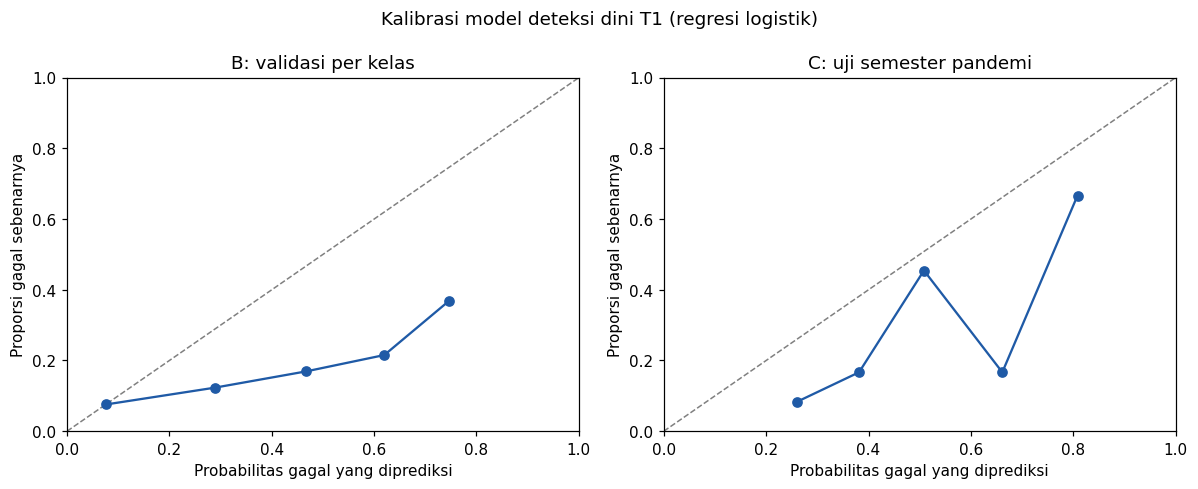

In [10]:
TK, NM = 'T1 Sebelum UTS (+CW1)', 'Regresi logistik'
pB, pC = oof[(TK, NM)], pred_C[(TK, NM)]

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a, (yy, pp, judul) in zip(ax, [(y, pB, 'B: validasi per kelas'), (y[te], pC, 'C: uji semester pandemi')]):
    q = pd.qcut(pp, 5, duplicates='drop')
    g = pd.DataFrame({'p': pp, 'y': yy}).groupby(q, observed=True).mean()
    a.plot([0, 1], [0, 1], '--', color='grey', lw=1)
    a.plot(g.p, g.y, 'o-', color='#1f5aa6')
    a.set_xlabel('Probabilitas gagal yang diprediksi'); a.set_ylabel('Proporsi gagal sebenarnya'); a.set_title(judul)
    a.set_xlim(0, 1); a.set_ylim(0, 1)
plt.suptitle('Kalibrasi model deteksi dini T1 (regresi logistik)'); plt.tight_layout()
plt.savefig('Gambar_Kalibrasi_T1.png', dpi=200, bbox_inches='tight'); plt.show()

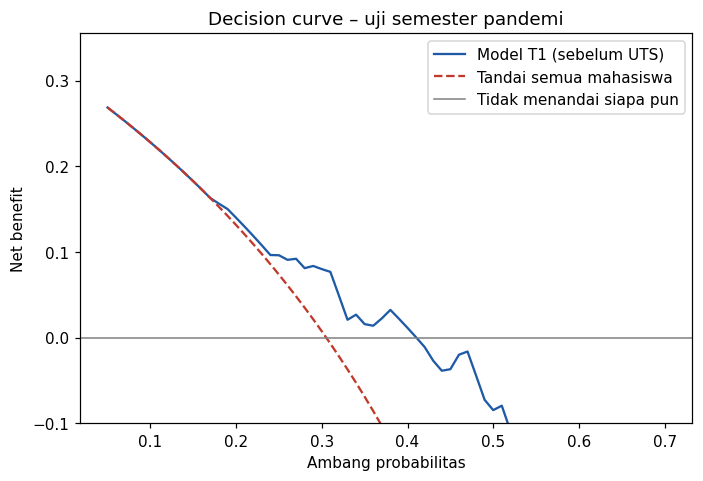

In [11]:
def net_benefit(yt, p, thr):
    n = len(yt); tp = ((p >= thr) & (yt == 1)).sum(); fp = ((p >= thr) & (yt == 0)).sum()
    return tp / n - fp / n * thr / (1 - thr)

thr = np.arange(0.05, 0.71, 0.01)
yt, pp = y[te], pC
prev = yt.mean()
nb_model = [net_benefit(yt, pp, t) for t in thr]
nb_all = [prev - (1 - prev) * t / (1 - t) for t in thr]
plt.figure(figsize=(6.5, 4.5))
plt.plot(thr, nb_model, label='Model T1 (sebelum UTS)', color='#1f5aa6')
plt.plot(thr, nb_all, label='Tandai semua mahasiswa', color='#c0392b', ls='--')
plt.axhline(0, color='grey', lw=1, label='Tidak menandai siapa pun')
plt.ylim(-0.1, max(prev, max(nb_model)) + 0.05); plt.xlabel('Ambang probabilitas'); plt.ylabel('Net benefit')
plt.title('Decision curve – uji semester pandemi'); plt.legend(); plt.tight_layout()
plt.savefig('Gambar_Decision_Curve_T1.png', dpi=200, bbox_inches='tight'); plt.show()

In [12]:
# Beban dosen: jika dosen hanya sanggup mendampingi k% mahasiswa per kelas
rows = []
for k in [0.10, 0.20, 0.30, 0.40]:
    for nama, yy, pp, g in [('B validasi per kelas', y, pB, groups), ('C semester pandemi', y[te], pC, groups[te])]:
        flag = np.zeros(len(pp), int)
        for gg in np.unique(g):
            idx = np.where(g == gg)[0]; n_flag = max(1, int(round(k * len(idx))))
            flag[idx[np.argsort(-pp[idx])[:n_flag]]] = 1
        rows.append({'Skenario': nama, 'Didampingi per kelas': f'{int(k*100)}%',
                     'Mhs ditandai per 25 mhs': round(k * 25), 'Gagal tertangkap (sensitivitas)': recall_score(yy, flag),
                     'Ketepatan tanda (presisi)': precision_score(yy, flag, zero_division=0)})
tab_beban = pd.DataFrame(rows)
tab_beban.round(3)

,Skenario,Didampingi per kelas,Mhs ditandai per 25 mhs,Gagal tertangkap (sensitivitas),Ketepatan tanda (presisi)
0,B validasi per kelas,10%,2,0.129,0.229
1,C semester pandemi,10%,2,0.111,0.333
2,B validasi per kelas,20%,5,0.274,0.258
3,C semester pandemi,20%,5,0.278,0.417
4,B validasi per kelas,30%,8,0.403,0.258
5,C semester pandemi,30%,8,0.556,0.556
6,B validasi per kelas,40%,10,0.484,0.231
7,C semester pandemi,40%,10,0.667,0.500


## 9. Faktor yang paling menentukan risiko dan analisis sensitivitas

In [13]:
# Koefisien regresi logistik (T1, dilatih pada semua data) + permutation importance pada uji pandemi
cols = FITUR[TK]
lr = model_dict()[NM].fit(X[cols].values, y)
coef = pd.Series(lr[-1].coef_[0], index=cols).sort_values(key=abs, ascending=False)
mC = model_dict()[NM].fit(X[cols].values[tr], y[tr])
pi = permutation_importance(mC, X[cols].values[te], y[te], scoring='roc_auc', n_repeats=200, random_state=SEED)
tab_fitur = pd.DataFrame({'Koefisien (terstandar)': coef, 'Penurunan AUC jika diacak (uji pandemi)': pd.Series(pi.importances_mean, index=cols)}).round(3)
tab_fitur['Odds ratio per 1 SD'] = np.exp(tab_fitur['Koefisien (terstandar)']).round(2)
tab_fitur

,Koefisien (terstandar),Penurunan AUC jika diacak (uji pandemi),Odds ratio per 1 SD
AtRisk,0.008,-0.007,1.01
AtRiskSSC,-0.322,0.000,0.72
CW1,-1.039,0.222,0.35
HighRisk,0.172,-0.001,1.19
IPK,0.027,-0.003,1.03
Jumlah_percobaan,-0.075,0.008,0.93
MK_M2,-0.619,0.000,0.54
MK_M3,0.255,0.000,1.29
MK_M4,-0.247,0.000,0.78
MK_M5,0.229,0.000,1.26


In [14]:
# Nilai tambah tiap sumber data (validasi per kelas, regresi logistik)
nt = tab_B[tab_B.Model == NM][['Titik keputusan', 'AUC_rata2_ulangan', 'AUC_CI_bawah', 'AUC_CI_atas', 'PR-AUC']].reset_index(drop=True)
nt['Tambahan AUC'] = nt.AUC_rata2_ulangan.diff()
nt.round(3)

,Titik keputusan,AUC_rata2_ulangan,AUC_CI_bawah,AUC_CI_atas,PR-AUC,Tambahan AUC
0,T0 Awal semester (SIAKAD),0.602,0.542,0.660,0.257,NaN
1,T1 Sebelum UTS (+CW1),0.676,0.596,0.719,0.336,0.074
2,T1+ (+LMS & video),0.674,0.620,0.716,0.339,-0.002
3,Penuh (+CW2 & UAS),0.668,0.608,0.717,0.352,-0.006


In [15]:
# Sensitivitas: tanpa kelas M3_SP17 (ID dicocokkan berdasarkan urutan) dan khusus mata kuliah pemrograman (Modul 1)
rows = []
for nama, mask in [('Tanpa M3_SP17', df.key.values != 'M3_SP17'), ('Hanya Modul 1 (OOP)', df.modul.values == 'M1')]:
    Xa, ya_, ga = X[FITUR[TK]].values[mask], y[mask], groups[mask]
    nsp = min(5, len(np.unique(ga))); aucs = []
    for r in range(N_REP):
        p = np.zeros(len(ya_))
        for trn, tst in grup_folds(ga, nsp, SEED + r):
            p[tst] = model_dict()[NM].fit(Xa[trn], ya_[trn]).predict_proba(Xa[tst])[:, 1]
        aucs.append(roc_auc_score(ya_, p))
    rows.append({'Analisis': nama, 'n': int(mask.sum()), 'Gagal': int(ya_.sum()), 'AUC rata-rata': np.mean(aucs),
                 'P2.5': np.percentile(aucs, 2.5), 'P97.5': np.percentile(aucs, 97.5)})
tab_sens = pd.DataFrame(rows)
tab_sens.round(3)

,Analisis,n,Gagal,AUC rata-rata,P2.5,P97.5
0,Tanpa M3_SP17,305,60,0.679,0.630,0.714
1,Hanya Modul 1 (OOP),138,42,0.646,0.623,0.665


## 10. Analisis statistik pendukung

Bagian ini melengkapi evaluasi model dengan uji statistik klasik:

- (a) kecukupan sampel (*events per variable*);
- (b) perbedaan tingkat gagal pra-pandemi vs pandemi;
- (c) perbandingan mahasiswa lulus vs gagal pada prediktor utama, dengan uji nonparametrik dan ukuran efek;
- (d) regresi logistik inferensial (odds ratio, CI 95%, p) dan multikolinearitas (VIF);
- (e) uji beda AUC antar-titik keputusan (DeLong dan *bootstrap* berpasangan);
- (f) interval kepercayaan Wilson untuk proporsi mahasiswa gagal yang terjangkau dosen.

Semua dihitung dengan numpy/scipy, tanpa paket tambahan.

In [16]:
# 10a. Kecukupan sampel: events per variable (EPV)
n_event = int(y.sum())
epv = pd.DataFrame([{'Titik keputusan': tk, 'Jumlah prediktor': len(c), 'Kejadian (gagal)': n_event,
                     'EPV': round(n_event / len(c), 1)} for tk, c in FITUR.items()])
# 10b. Pergeseran tingkat gagal antar-periode
ct = pd.crosstab(df.periode, df.gagal)
chi2, p_chi, dof, _ = stats.chi2_contingency(ct, correction=False)
a, b_ = ct.loc['Pandemi 2020-21', 1], ct.loc['Pandemi 2020-21', 0]
c_, d_ = ct.loc['Pra-pandemi 2017-19', 1], ct.loc['Pra-pandemi 2017-19', 0]
OR = (a * d_) / (b_ * c_); se = np.sqrt(1/a + 1/b_ + 1/c_ + 1/d_)
or_ci = np.exp(np.log(OR) + np.array([-1.96, 1.96]) * se)
_, p_fisher = stats.fisher_exact([[a, b_], [c_, d_]])
print(f'Gagal pandemi {a}/{a+b_} ({a/(a+b_):.1%}) vs pra-pandemi {c_}/{c_+d_} ({c_/(c_+d_):.1%}); '
      f'chi2({dof}) = {chi2:.2f}, p = {p_chi:.3f}; Fisher p = {p_fisher:.3f}; OR = {OR:.2f} [{or_ci[0]:.2f}, {or_ci[1]:.2f}]')
epv

Gagal pandemi 18/59 (30.5%) vs pra-pandemi 44/267 (16.5%); chi2(1) = 6.18, p = 0.013; Fisher p = 0.017; OR = 2.23 [1.17, 4.23]


,Titik keputusan,Jumlah prediktor,Kejadian (gagal),EPV
0,T0 Awal semester (SIAKAD),15,62,4.1
1,T1 Sebelum UTS (+CW1),16,62,3.9
2,T1+ (+LMS & video),22,62,2.8
3,Penuh (+CW2 & UAS),24,62,2.6


In [17]:
# 10c. Lulus vs gagal: Shapiro-Wilk -> Mann-Whitney U + rank-biserial; variabel biner -> chi-square/Fisher + phi
rows = []
for c in ['IPK', 'CW1', 'Modul_lain', 'Moodle_kampus', 'Moodle_luar', 'Video_Played', 'Video_Paused']:
    g1, g0 = X.loc[y == 1, c].dropna(), X.loc[y == 0, c].dropna()
    sw_p = stats.shapiro(X[c].dropna()).pvalue
    U, p = stats.mannwhitneyu(g1, g0, alternative='two-sided')
    rb = 1 - 2 * U / (len(g1) * len(g0))   # rank-biserial (positif = kelompok gagal lebih rendah)
    rows.append({'Variabel': c, 'Gagal Mdn (IQR)': f'{g1.median():.2f} ({g1.quantile(.25):.2f}-{g1.quantile(.75):.2f})',
                 'Lulus Mdn (IQR)': f'{g0.median():.2f} ({g0.quantile(.25):.2f}-{g0.quantile(.75):.2f})',
                 'Shapiro p': sw_p, 'Uji': 'Mann-Whitney U', 'Statistik': U, 'p': p, 'Efek (r rank-biserial)': rb})
for c in ['AtRisk', 'HighRisk', 'Probation', 'Prasyarat_tidak_lulus', 'Riwayat_plagiarisme']:
    t = pd.crosstab(X[c], y)
    if t.shape == (2, 2):
        chi, p, _, ex = stats.chi2_contingency(t, correction=False)
        uji = 'Chi-square'
        if (ex < 5).any():
            _, p = stats.fisher_exact(t.values); uji = 'Fisher exact'
        phi = np.sqrt(chi / t.values.sum())
        rows.append({'Variabel': c, 'Gagal Mdn (IQR)': f'{X.loc[y==1, c].mean():.1%} ya', 'Lulus Mdn (IQR)': f'{X.loc[y==0, c].mean():.1%} ya',
                     'Shapiro p': np.nan, 'Uji': uji, 'Statistik': chi, 'p': p, 'Efek (r rank-biserial)': phi})
tab_uji = pd.DataFrame(rows)
# koreksi Holm untuk 12 uji
order = np.argsort(tab_uji.p.values); m = len(order); adj = np.empty(m); run = 0
for k, i in enumerate(order):
    run = max(run, min(1, (m - k) * tab_uji.p.values[i])); adj[i] = run
tab_uji['p Holm'] = adj
tab_uji.round(4)

,Variabel,Gagal Mdn (IQR),Lulus Mdn (IQR),Shapiro p,Uji,Statistik,p,Efek (r rank-biserial),p Holm
0,IPK,2.50 (2.00-3.00),2.25 (2.00-2.75),0.0,Mann-Whitney U,9035.5000,0.1639,-0.1125,0.9987
1,CW1,26.50 (19.25-48.00),55.08 (37.69-73.00),0.0,Mann-Whitney U,4527.0000,0.0000,0.4468,0.0000
2,Modul_lain,2.50 (2.00-3.00),3.00 (2.00-3.00),0.0,Mann-Whitney U,6764.0000,0.0194,0.1735,0.1745
3,Moodle_kampus,193.50 (129.50-351.25),186.50 (115.00-281.75),0.0,Mann-Whitney U,9163.5000,0.1427,-0.1197,0.9987
4,Moodle_luar,179.00 (81.25-296.50),184.00 (87.00-278.50),0.0,Mann-Whitney U,8289.0000,0.8757,-0.0128,1.0000
5,Video_Played,3.00 (1.00-4.75),1.00 (1.00-3.00),0.0,Mann-Whitney U,10255.0000,0.0008,-0.2531,0.0085
6,Video_Paused,2.00 (0.00-4.00),1.00 (0.00-3.00),0.0,Mann-Whitney U,9394.0000,0.0616,-0.1478,0.4932
7,AtRisk,17.7% ya,25.0% ya,NaN,Chi-square,1.4661,0.2260,0.0671,1.0000
8,HighRisk,6.5% ya,6.8% ya,NaN,Fisher exact,0.0107,1.0000,0.0057,1.0000
9,Probation,1.6% ya,3.8% ya,NaN,Fisher exact,0.7285,0.6971,0.0473,1.0000


In [18]:
# 10d. Regresi logistik inferensial (T1, prediktor terstandar) dengan MLE Newton-Raphson; VIF
def logit_mle(Xm, yv, iters=100):
    Xd = np.column_stack([np.ones(len(Xm)), Xm]); beta = np.zeros(Xd.shape[1])
    for _ in range(iters):
        pr = 1 / (1 + np.exp(-Xd @ beta)); W = pr * (1 - pr)
        H = Xd.T @ (Xd * W[:, None]); g = Xd.T @ (yv - pr)
        step = np.linalg.solve(H, g); beta += step
        if np.max(np.abs(step)) < 1e-8: break
    se = np.sqrt(np.diag(np.linalg.inv(H)))
    ll = np.sum(yv * np.log(pr) + (1 - yv) * np.log(1 - pr))
    return beta, se, ll

cols_inf = ['IPK', 'Jumlah_percobaan', 'AtRisk', 'HighRisk', 'Probation', 'Modul_lain', 'Prasyarat_tidak_lulus',
            'Riwayat_plagiarisme', 'MK_M2', 'MK_M3', 'MK_M4', 'MK_M5', 'CW1']
Xi = X[cols_inf].copy(); Xi['IPK'] = Xi['IPK'].fillna(Xi['IPK'].median())
Z = ((Xi - Xi.mean()) / Xi.std()).values
beta, se, ll = logit_mle(Z, y.astype(float))
_, _, ll0 = logit_mle(np.empty((len(y), 0)), y.astype(float))
LR = 2 * (ll - ll0); p_LR = stats.chi2.sf(LR, len(cols_inf)); r2_mcf = 1 - ll / ll0
zval = beta / se; pv = 2 * stats.norm.sf(np.abs(zval))
vif = [1 / (1 - (1 - np.sum((Z[:, j] - np.column_stack([np.ones(len(Z)), np.delete(Z, j, 1)]) @
         np.linalg.lstsq(np.column_stack([np.ones(len(Z)), np.delete(Z, j, 1)]), Z[:, j], rcond=None)[0]) ** 2) / np.sum((Z[:, j] - Z[:, j].mean()) ** 2)))
       for j in range(Z.shape[1])]
tab_logit = pd.DataFrame({'Prediktor': ['(Intercept)'] + cols_inf, 'B': beta, 'SE': se, 'z': zval, 'p': pv,
                          'OR per 1 SD': np.exp(beta), 'OR CI bawah': np.exp(beta - 1.96 * se), 'OR CI atas': np.exp(beta + 1.96 * se),
                          'VIF': [np.nan] + vif})
print(f'Model T1: LR chi2({len(cols_inf)}) = {LR:.2f}, p = {p_LR:.4f}, McFadden R2 = {r2_mcf:.3f}, n = {len(y)}, kejadian = {int(y.sum())}')
print('Catatan: TermExceeded, AtRiskSSC, dan Riwayat_kecurangan tidak dimasukkan di model inferensial karena sangat jarang (<= 6%) sehingga estimasi tidak stabil.')
tab_logit.round(3)

Model T1: LR chi2(13) = 49.58, p = 0.0000, McFadden R2 = 0.156, n = 326, kejadian = 62
Catatan: TermExceeded, AtRiskSSC, dan Riwayat_kecurangan tidak dimasukkan di model inferensial karena sangat jarang (<= 6%) sehingga estimasi tidak stabil.


,Prediktor,B,SE,z,p,OR per 1 SD,OR CI bawah,OR CI atas,VIF
0,(Intercept),-1.924,0.228,-8.430,0.000,0.146,0.093,0.228,NaN
1,IPK,0.084,0.190,0.441,0.659,1.087,0.749,1.577,1.454
2,Jumlah_percobaan,0.029,0.220,0.133,0.894,1.030,0.669,1.586,1.665
3,AtRisk,-0.159,0.196,-0.807,0.419,0.853,0.581,1.254,1.476
4,HighRisk,0.159,0.178,0.895,0.371,1.172,0.828,1.661,1.391
5,Probation,-0.159,0.240,-0.662,0.508,0.853,0.533,1.366,1.341
6,Modul_lain,-0.406,0.179,-2.261,0.024,0.666,0.469,0.947,1.243
7,Prasyarat_tidak_lulus,-0.145,0.157,-0.920,0.358,0.865,0.636,1.178,1.609
8,Riwayat_plagiarisme,-0.080,0.163,-0.493,0.622,0.923,0.671,1.269,1.146
9,MK_M2,-0.729,0.400,-1.824,0.068,0.482,0.220,1.056,2.027


In [19]:
# 10e. Uji beda AUC: DeLong (berkorelasi, sampel sama) dan bootstrap berpasangan
def delong(y_true, p1, p2):
    pos, neg = p1[y_true == 1], p1[y_true == 0]; pos2, neg2 = p2[y_true == 1], p2[y_true == 0]
    def comps(pp, nn):
        psi = (pp[:, None] > nn[None, :]) + 0.5 * (pp[:, None] == nn[None, :])
        return psi.mean(), psi.mean(axis=1), psi.mean(axis=0)
    a1, v10_1, v01_1 = comps(pos, neg); a2, v10_2, v01_2 = comps(pos2, neg2)
    S10 = np.cov(np.vstack([v10_1, v10_2])); S01 = np.cov(np.vstack([v01_1, v01_2]))
    S = S10 / len(pos) + S01 / len(neg); d = a1 - a2
    var = S[0, 0] + S[1, 1] - 2 * S[0, 1]; zz = d / np.sqrt(var)
    return a1, a2, d, zz, 2 * stats.norm.sf(abs(zz))

def boot_diff(y_true, p1, p2, n=N_BOOT, seed=SEED):
    r = np.random.default_rng(seed); ds = []; idx = np.arange(len(y_true))
    while len(ds) < n:
        b = r.choice(idx, len(idx))
        if y_true[b].min() == y_true[b].max(): continue
        ds.append(roc_auc_score(y_true[b], p1[b]) - roc_auc_score(y_true[b], p2[b]))
    return np.percentile(ds, [2.5, 97.5])

rows = []
pairs = [('T1 Sebelum UTS (+CW1)', 'T0 Awal semester (SIAKAD)'), ('T1+ (+LMS & video)', 'T1 Sebelum UTS (+CW1)')]
for nama, yy, P in [('B validasi per kelas', y, oof), ('C semester pandemi', y[te], pred_C)]:
    for t_a, t_b in pairs:
        a1, a2, d, zz, pz = delong(yy, P[(t_a, NM)], P[(t_b, NM)])
        lo, hi = boot_diff(yy, P[(t_a, NM)], P[(t_b, NM)])
        rows.append({'Skenario': nama, 'Perbandingan': f'{t_a.split()[0]} vs {t_b.split()[0]}', 'AUC A': a1, 'AUC B': a2,
                     'Selisih': d, 'z DeLong': zz, 'p DeLong': pz, 'CI95 bootstrap bawah': lo, 'CI95 bootstrap atas': hi})
tab_delong = pd.DataFrame(rows)
tab_delong.round(3)

,Skenario,Perbandingan,AUC A,AUC B,Selisih,z DeLong,p DeLong,CI95 bootstrap bawah,CI95 bootstrap atas
0,B validasi per kelas,T1 vs T0,0.688,0.613,0.075,3.172,0.002,0.032,0.123
1,B validasi per kelas,T1+ vs T1,0.686,0.688,-0.002,-0.087,0.931,-0.052,0.048
2,C semester pandemi,T1 vs T0,0.713,0.568,0.145,3.398,0.001,0.062,0.236
3,C semester pandemi,T1+ vs T1,0.676,0.713,-0.037,-0.401,0.688,-0.222,0.137


In [20]:
# 10f. Interval Wilson untuk proporsi mahasiswa gagal yang terjangkau (tabel beban dosen)
def wilson(k, n, z=1.96):
    if n == 0: return np.nan, np.nan
    ph = k / n; den = 1 + z**2 / n; cen = (ph + z**2 / (2 * n)) / den
    half = z * np.sqrt(ph * (1 - ph) / n + z**2 / (4 * n**2)) / den
    return cen - half, cen + half
tb = tab_beban.copy()
nfail = {'B validasi per kelas': int(y.sum()), 'C semester pandemi': int(y[te].sum())}
tb['Gagal terjangkau (n)'] = [int(round(r['Gagal tertangkap (sensitivitas)'] * nfail[r['Skenario']])) for _, r in tb.iterrows()]
tb['Total gagal'] = tb.Skenario.map(nfail)
ci = [wilson(k, n) for k, n in zip(tb['Gagal terjangkau (n)'], tb['Total gagal'])]
tb['Wilson CI bawah'] = [c[0] for c in ci]; tb['Wilson CI atas'] = [c[1] for c in ci]
tab_beban = tb
tab_beban.round(3)

,Skenario,Didampingi per kelas,Mhs ditandai per 25 mhs,Gagal tertangkap (sensitivitas),Ketepatan tanda (presisi),Gagal terjangkau (n),Total gagal,Wilson CI bawah,Wilson CI atas
0,B validasi per kelas,10%,2,0.129,0.229,8,62,0.067,0.234
1,C semester pandemi,10%,2,0.111,0.333,2,18,0.031,0.328
2,B validasi per kelas,20%,5,0.274,0.258,17,62,0.179,0.396
3,C semester pandemi,20%,5,0.278,0.417,5,18,0.125,0.509
4,B validasi per kelas,30%,8,0.403,0.258,25,62,0.290,0.527
5,C semester pandemi,30%,8,0.556,0.556,10,18,0.337,0.754
6,B validasi per kelas,40%,10,0.484,0.231,30,62,0.364,0.606
7,C semester pandemi,40%,10,0.667,0.500,12,18,0.437,0.837


## 11. Menyimpan hasil

In [21]:
with pd.ExcelWriter('Hasil_Deteksi_Dini.xlsx') as w:
    pd.crosstab(df.periode, df.Result, margins=True).to_excel(w, sheet_name='1_Data')
    X.describe().T.round(3).to_excel(w, sheet_name='2_Deskriptif')
    tab_A.round(4).to_excel(w, sheet_name='3_Replikasi_studi_lama', index=False)
    tab_B.round(4).to_excel(w, sheet_name='4_Validasi_per_kelas', index=False)
    tab_C.round(4).to_excel(w, sheet_name='5_Validasi_waktu', index=False)
    ring.round(4).to_excel(w, sheet_name='6_Ringkasan', index=False)
    tab_beban.round(4).to_excel(w, sheet_name='7_Beban_dosen', index=False)
    tab_fitur.to_excel(w, sheet_name='8_Faktor_risiko')
    nt.round(4).to_excel(w, sheet_name='9_Nilai_tambah_sumber', index=False)
    tab_sens.round(4).to_excel(w, sheet_name='10_Sensitivitas', index=False)
    epv.to_excel(w, sheet_name='11_EPV', index=False)
    tab_uji.round(4).to_excel(w, sheet_name='12_Uji_lulus_vs_gagal', index=False)
    tab_logit.round(4).to_excel(w, sheet_name='13_Logit_inferensial', index=False)
    tab_delong.round(4).to_excel(w, sheet_name='14_Uji_beda_AUC', index=False)
    tab_A_rep.round(4).to_excel(w, sheet_name='15_Replikasi_20_split', index=False)
import sys, sklearn
print('Tersimpan: Hasil_Deteksi_Dini.xlsx, Gambar_Kalibrasi_T1.png, Gambar_Decision_Curve_T1.png')
print('Python', sys.version.split()[0], '| numpy', np.__version__, '| pandas', pd.__version__, '| scikit-learn', sklearn.__version__)

Tersimpan: Hasil_Deteksi_Dini.xlsx, Gambar_Kalibrasi_T1.png, Gambar_Decision_Curve_T1.png
Python 3.11.15 | numpy 2.4.4 | pandas 3.0.2 | scikit-learn 1.8.0
